# Stop VLLM

In [ ]:
import subprocess
import psutil

def stop_vllm_server():
    try:
        
        for proc in psutil.process_iter(['pid','name','cmdline']):
            if 'vllm' in proc.info['name'].lower():
                print(proc)
                vllm_process_info = proc.info
                proc.kill()
                print(f"Found VLLM server running, PID: {vllm_process_info['pid']}, and killed vllm server")
                print("vllm server stopped successfully.")
    except subprocess.CalledProcessError as e:
        print(f"Error stopping vllm server: {e}")

In [ ]:
import subprocess
def stop_ollama(model_name):
    try:
        subprocess.Popen(
            f"ollama stop {model_name}",
            shell=True
        )
        print(f"Stopped ollama Successfully")
    except Exception as e:
        print(f"Error: {e}")

In [ ]:
stop_ollama('deepseek-r1:8b')

Stopped ollama Successfully


# VLLM Chat Models

In [1]:
from vllm import LLM, SamplingParams

/home/vignesh/.nlpvenv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Standard Test

In [2]:
prompts = [
    "Hello, my name is",
    "The president of the United States is",
    "The capital of France is",
    "The future of AI is",
]
sampling_params = SamplingParams(temperature=0.8, top_p=0.95)

In [3]:
llm = LLM(model="facebook/opt-125m")

INFO 09-12 11:19:08 [api_utils.py:286] non-default args: {'disable_log_stats': True, 'model': 'facebook/opt-125m'}
INFO 09-12 11:19:10 [model.py:684] Resolved architecture: OPTForCausalLM
INFO 09-12 11:19:10 [model.py:2021] Using max model len 2048
INFO 09-12 11:19:10 [scheduler.py:277] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 09-12 11:19:11 [kernel.py:369] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'])
(EngineCore pid=12725) INFO 09-12 11:19:12 [core.py:123] Initializing a V1 LLM engine (v0.29.0) with config: model='facebook/opt-125m', speculative_config=None, tokenizer='facebook/opt-125m', skip_tokenizer_init=False, tokenizer_mode=auto, revision=main, tokenizer_revision=main, trust_remote_code=False, dtype=torch.float16, max_seq_len=2048, download_dir=None, load_format=auto, tensor_parallel_size=1, pipeline_parallel_size=1, data_parallel_size=1, decode_context_parallel_size=1, dcp_c

Loading pt checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading pt checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  1.50it/s]
Loading pt checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  1.49it/s]
(EngineCore pid=12725) 


(EngineCore pid=12725) INFO 09-12 11:19:16 [default_loader.py:430] Loading weights took 0.68 seconds
(EngineCore pid=12725) INFO 09-12 11:19:16 [model_runner.py:404] Model loading took 0.24 GiB memory and 2.910799 seconds
(EngineCore pid=12725) INFO 09-12 11:19:16 [topk_topp_sampler.py:62] Using FlashInfer for top-p & top-k sampling.
(EngineCore pid=12725) INFO 09-12 11:19:16 [utils.py:306] Using LBNHC KV cache layout.
(EngineCore pid=12725) INFO 09-12 11:19:18 [caching.py:343] reconstructed serializable fn from standalone compile artifacts. num_artifacts=3 num_submods=13
(EngineCore pid=12725) INFO 09-12 11:19:18 [decorators.py:313] Directly load AOT compilation from path /home/vignesh/.cache/vllm/torch_compile_cache/torch_aot_compile/1cc8b008434711554eea7daf1b35ea28c81d63441a514ac32c662aed24173265/rank_0_0/model
(EngineCore pid=12725) INFO 09-12 11:19:18 [monitor.py:53] torch.compile took 0.17 s in total
(EngineCore pid=12725) INFO 09-12 11:19:18 [monitor.py:81] Initial profiling/war

Capturing CUDA graphs (FULL): 100%|██████████| 2/2 [00:00<00:00, 64.01it/s]


(EngineCore pid=12725) INFO 09-12 11:19:21 [model_runner.py:960] Graph capturing finished in 2 secs, took 0.13 GiB
(EngineCore pid=12725) INFO 09-12 11:19:21 [gpu_worker.py:625] Available KV cache memory: 6.22 GiB
(EngineCore pid=12725) INFO 09-12 11:19:21 [gpu_worker.py:640] CUDA graph memory profiling is enabled (default since v0.21.0). The current --gpu-memory-utilization=0.9200 is equivalent to --gpu-memory-utilization=0.8948 without CUDA graph memory profiling. To maintain the same effective KV cache size as before, increase --gpu-memory-utilization to 0.9452. To disable, set VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS=0.
(EngineCore pid=12725) INFO 09-12 11:19:21 [kv_cache_utils.py:2032] GPU KV cache size: 181,104 tokens, Maximum concurrency for 2,048 tokens per request: 88.43x
(EngineCore pid=12725) INFO 09-12 11:19:21 [kernel_warmup.py:124] JIT kernel warmup starting.
(EngineCore pid=12725) INFO 09-12 11:19:21 [kernel_warmup.py:134] JIT kernel warmup finished in 0.00s.


Capturing CUDA graphs (FULL): 100%|██████████| 35/35 [00:00<00:00, 101.70it/s]


(EngineCore pid=12725) INFO 09-12 11:19:23 [model_runner.py:960] Graph capturing finished in 2 secs, took 0.07 GiB
(EngineCore pid=12725) INFO 09-12 11:19:23 [gpu_worker.py:797] CUDA graph pool memory: 0.07 GiB (actual), 0.19 GiB (estimated), difference: 0.12 GiB (162.2%).
(EngineCore pid=12725) INFO 09-12 11:19:23 [gpu_worker.py:860] Free memory on device (7.44/7.53 GiB) on startup. Desired GPU memory utilization is (0.92, 6.92 GiB). Actual usage is 0.42 GiB for consumed memory (weights + non-torch), 0.28 GiB for peak activation, and 0.07 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=6441472758` (6.0 GiB) to fit into requested memory, or `--kv-cache-memory=6990326272` (6.51 GiB) to fully utilize gpu memory. Current kv cache memory in use is 6.22 GiB.
(EngineCore pid=12725) INFO 09-12 11:19:24 [jit_monitor.py:85] Kernel JIT monitor activated; monitored JIT compilations during inference will use mode=warn.
(EngineCore pid=12725) INFO 09-12 11:19

In [4]:
outputs = llm.generate(prompts, sampling_params)

for output in outputs:
    prompt = output.prompt
    generated_text = output.outputs[0].text
    print(f"Prompt: {prompt!r}, Generated text: {generated_text!r}")

Processed prompts: 100%|██████████| 4/4 [00:00<00:00, 125.29it/s, est. speed input: 837.19 toks/s, output: 2060.29 toks/s]

Prompt: 'Hello, my name is', Generated text: " Michael. I'm a manager of The Prudential Financial Trust, based in"
Prompt: 'The president of the United States is', Generated text: ' signing an executive order that will force the Pentagon to lift the nation’s'
Prompt: 'The capital of France is', Generated text: ' expected to host the World Cup, with the country’s soccer federation hoping'
Prompt: 'The future of AI is', Generated text: ' pretty bleak.   They are still a bit of a grind.  '


In [ ]:
import psutil
for proc in psutil.process_iter(['pid','name','cmdline']):
    if 'vllm' in proc.info['name'].lower():
        print(proc)
        vllm_process_info = proc.info
        proc.kill()
        print(f"Found VLLM server running, PID: {vllm_process_info['pid']}, and killed vllm server")
        # print(vllm_process_info)
    # print(proc)

psutil.Process(pid=15483, name='VLLM::EngineCore', status='sleeping')
Found VLLM server running, PID: 15483, and killed vllm server


INFO 09-11 12:10:41 [utils.py:620] [shutdown] Process manager: send sigterm to process EngineCore
WARNING 09-11 12:10:42 [core_client.py:728] [shutdown] MPClient: engine core exited unexpectedly; starting cleanup
INFO 09-11 12:10:42 [core_client.py:689] [shutdown] MPClient: start timeout=default
INFO 09-11 12:10:42 [core_client.py:691] [shutdown] MPClient: stopping engine manager
INFO 09-11 12:10:42 [core_client.py:693] [shutdown] MPClient: engine manager stopped
INFO 09-11 12:10:42 [core_client.py:694] [shutdown] MPClient: cleaning up background resources
INFO 09-11 12:10:42 [core_client.py:696] [shutdown] MPClient: complete


In [ ]:
stop_vllm_server()

psutil.Process(pid=12725, name='VLLM::EngineCore', status='sleeping')
Found VLLM server running, PID: 12725, and killed vllm server
vllm server stopped successfully.


INFO 09-12 11:20:08 [utils.py:620] [shutdown] Process manager: send sigterm to process EngineCore
WARNING 09-12 11:20:09 [core_client.py:728] [shutdown] MPClient: engine core exited unexpectedly; starting cleanup
INFO 09-12 11:20:09 [core_client.py:689] [shutdown] MPClient: start timeout=default
INFO 09-12 11:20:09 [core_client.py:691] [shutdown] MPClient: stopping engine manager
INFO 09-12 11:20:09 [core_client.py:693] [shutdown] MPClient: engine manager stopped
INFO 09-12 11:20:09 [core_client.py:694] [shutdown] MPClient: cleaning up background resources
INFO 09-12 11:20:09 [core_client.py:696] [shutdown] MPClient: complete


In [9]:
# !kill -15 109386

## Llama 2:7b chat model

In [ ]:
# llm = LLM(
#     #    model="TheBloke/Llama-2-7b-Chat-AWQ",
#     model = 'meta-llama/Llama-2-7b-chat-hf',
#     # quantization="awq",
#     dtype="float16",
#     gpu_memory_utilization=0.85,
#     max_model_len=4048,   # lower this if you still OOM
#    )
# from vllm import LLM

llm = LLM(
    model="meta-llama/Llama-2-7b-chat-hf",   # uses your existing HF cache, no re-download
    dtype="float16",
    gpu_memory_utilization=0.95,
    cpu_offload_gb=8,          # GB of weights to push to CPU RAM
    max_model_len=4048,        # keep this modest — KV cache still eats VRAM
    enforce_eager=True,        # CUDA graphs + offloading don't always play nice; safer to disable
    # tensor_parallel_size=2,
)

INFO 09-12 11:27:38 [api_utils.py:286] non-default args: {'dtype': 'float16', 'max_model_len': 4048, 'cpu_offload_gb': 8, 'gpu_memory_utilization': 0.95, 'disable_log_stats': True, 'enforce_eager': True, 'model': 'meta-llama/Llama-2-7b-chat-hf'}
INFO 09-12 11:27:38 [model.py:684] Resolved architecture: LlamaForCausalLM
INFO 09-12 11:27:38 [model.py:2021] Using max model len 4048
INFO 09-12 11:27:38 [kernel.py:369] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['vllm_c', 'native'], fused_add_rms_norm=['vllm_c', 'native'])
(EngineCore pid=14150) INFO 09-12 11:27:39 [core.py:123] Initializing a V1 LLM engine (v0.29.0) with config: model='meta-llama/Llama-2-7b-chat-hf', speculative_config=None, tokenizer='meta-llama/Llama-2-7b-chat-hf', skip_tokenizer_init=False, tokenizer_mode=auto, revision=main, tokenizer_revision=main, trust_remote_code=False, dtype=torch.float16, max_seq_len=4048, download_dir=None, load_format=auto, tensor_parallel_size=1, pipeline

Loading safetensors checkpoint shards:   0% Completed | 0/2 [00:00<?, ?it/s]
Loading safetensors checkpoint shards:  50% Completed | 1/2 [00:22<00:22, 22.70s/it]
Loading safetensors checkpoint shards: 100% Completed | 2/2 [00:27<00:00, 12.32s/it]
Loading safetensors checkpoint shards: 100% Completed | 2/2 [00:27<00:00, 13.88s/it]
(EngineCore pid=14150) 


(EngineCore pid=14150) INFO 09-12 11:28:19 [default_loader.py:430] Loading weights took 27.78 seconds
(EngineCore pid=14150) INFO 09-12 11:28:20 [model_runner.py:404] Model loading took 4.54 GiB memory and 39.301989 seconds
(EngineCore pid=14150) INFO 09-12 11:28:20 [topk_topp_sampler.py:62] Using FlashInfer for top-p & top-k sampling.
(EngineCore pid=14150) INFO 09-12 11:28:20 [utils.py:306] Using LBNHC KV cache layout.


In [11]:
prompt = "why sky is blue?, explain briefly"

outputs = llm.generate(prompt, sampling_params)
print(outputs[0].outputs[0].text)

Processed prompts: 100%|██████████| 1/1 [00:19<00:00, 19.25s/it, est. speed input: 0.42 toks/s, output: 0.83 toks/s]



The sky appears blue because of a phenomenon called Rayleigh scatter


In [12]:
print(outputs)
print(outputs[0].outputs)

[RequestOutput(request_id=0, prompt='why sky is blue?, explain briefly', prompt_token_ids=[1, 2020, 14744, 338, 7254, 14579, 5649, 23359], encoder_prompt=None, encoder_prompt_token_ids=None, prompt_logprobs=None, outputs=[CompletionOutput(index=0, text='\n\nThe sky appears blue because of a phenomenon called Rayleigh scatter', token_ids=[13, 13, 1576, 14744, 5692, 7254, 1363, 310, 263, 27791, 265, 2000, 9596, 280, 1141, 14801], routed_experts=None, sampling_mask=None, cumulative_logprob=None, logprobs=None, finish_reason=length, stop_reason=None)], finished=True, metrics=None, lora_request=None, num_cached_tokens=0, num_cache_creation_tokens=0)]
[CompletionOutput(index=0, text='\n\nThe sky appears blue because of a phenomenon called Rayleigh scatter', token_ids=[13, 13, 1576, 14744, 5692, 7254, 1363, 310, 263, 27791, 265, 2000, 9596, 280, 1141, 14801], routed_experts=None, sampling_mask=None, cumulative_logprob=None, logprobs=None, finish_reason=length, stop_reason=None)]


In [13]:
prompt = "What is R2 score in machine learning?, how to evaluate a model using R2 score?"

outputs = llm.generate(prompt, sampling_params)
print(outputs[0].outputs[0].text)

Processed prompts: 100%|██████████| 1/1 [00:17<00:00, 17.99s/it, est. speed input: 1.11 toks/s, output: 0.89 toks/s]



R-squared, or R2, is a metric used to


In [ ]:
stop_vllm_server()

psutil.Process(pid=13300, name='VLLM::EngineCore', status='sleeping')
Found VLLM server running, PID: 13300, and killed vllm server
vllm server stopped successfully.


INFO 09-12 11:26:54 [utils.py:620] [shutdown] Process manager: send sigterm to process EngineCore
INFO 09-12 11:26:56 [core_client.py:689] [shutdown] MPClient: start timeout=default


# VLLM OCR Models

## Deepseek-ocr 3b

In [16]:
from vllm import LLM, SamplingParams
from vllm.model_executor.models.deepseek_ocr import NGramPerReqLogitsProcessor
from vllm.config import AttentionConfig
from vllm.v1.attention.backends.registry import AttentionBackendEnum

from PIL import Image

In [ ]:
llm = LLM(
    model="deepseek-ai/DeepSeek-OCR",
    enable_prefix_caching=False,
    mm_processor_cache_gb=0,
    logits_processors=[NGramPerReqLogitsProcessor],
    gpu_memory_utilization=0.90,
    cpu_offload_gb=3,
    attention_config=AttentionConfig(backend=AttentionBackendEnum.FLASH_ATTN),

)

INFO 10-03 23:13:17 [api_utils.py:286] non-default args: {'enable_prefix_caching': False, 'cpu_offload_gb': 3, 'gpu_memory_utilization': 0.9, 'disable_log_stats': True, 'mm_processor_cache_gb': 0, 'attention_config': AttentionConfig(backend=<AttentionBackendEnum.FLASH_ATTN: 'vllm.v1.attention.backends.flash_attn.FlashAttentionBackend'>, minimax_m3_msa_decode_backend='triton', backend_per_kind={}, flash_attn_version=None, flash_attn_max_num_splits_for_cuda_graph=32, tq_max_kv_splits_for_cuda_graph=32, use_trtllm_attention=None, disable_flashinfer_q_quantization=False, mla_prefill_backend=None, use_prefill_query_quantization=False, use_fp4_indexer_cache=None, indexer_kv_dtype='auto', use_non_causal=False, sparse_mla_force_mqa=False, flex_attn_block_m=None, flex_attn_block_n=None, flex_attn_q_block_size=None, flex_attn_kv_block_size=None), 'logits_processors': [<class 'vllm.model_executor.models.deepseek_ocr.NGramPerReqLogitsProcessor'>], 'model': 'deepseek-ai/DeepSeek-OCR'}
INFO 10-03 23

Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:16<00:00, 16.42s/it]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:16<00:00, 16.43s/it]
(EngineCore pid=233802) 


(EngineCore pid=233802) INFO 10-03 23:13:44 [default_loader.py:430] Loading weights took 16.48 seconds
(EngineCore pid=233802) INFO 10-03 23:13:44 [unquantized.py:399] Using MoEPrepareAndFinalizeNoDPEPModular
(EngineCore pid=233802) INFO 10-03 23:13:44 [unquantized.py:400] Using TritonExperts MoE backend
(EngineCore pid=233802) INFO 10-03 23:13:45 [gpu_model_runner.py:5471] Model loading took 3.21 GiB memory and 21.250752 seconds
(EngineCore pid=233802) INFO 10-03 23:13:45 [utils.py:306] Using LBNHC KV cache layout.
(EngineCore pid=233802) INFO 10-03 23:13:45 [gpu_model_runner.py:6546] Encoder cache will be initialized with a budget of 8192 tokens, and profiled with 11 image items of the maximum feature size.


(EngineCore pid=233802) Process EngineCore:
(EngineCore pid=233802) Traceback (most recent call last):
(EngineCore pid=233802)   File "/home/vignesh/.local/share/uv/python/cpython-3.10-linux-x86_64-gnu/lib/python3.10/multiprocessing/process.py", line 314, in _bootstrap
(EngineCore pid=233802)     self.run()
(EngineCore pid=233802)   File "/home/vignesh/.local/share/uv/python/cpython-3.10-linux-x86_64-gnu/lib/python3.10/multiprocessing/process.py", line 108, in run
(EngineCore pid=233802)     self._target(*self._args, **self._kwargs)
(EngineCore pid=233802)   File "/home/vignesh/.nlpvenv/lib/python3.10/site-packages/vllm/v1/engine/core.py", line 1336, in run_engine_core
(EngineCore pid=233802)     engine_core = EngineCoreProc(*args, engine_index=dp_rank, **kwargs)
(EngineCore pid=233802)   File "/home/vignesh/.nlpvenv/lib/python3.10/site-packages/vllm/tracing/otel.py", line 178, in sync_wrapper
(EngineCore pid=233802)     return func(*args, **kwargs)
(EngineCore pid=233802)   File "/hom

In [ ]:
image_path_1 = 'inputs/images/sample_image.jpg'
image_path_2 = 'inputs/images/first_30_pages-01.jpg'
image_1 = Image.open(image_path_1)
image_2 = Image.open(image_path_2)
# image_1.show()

prompt = "<image>\nFree OCR."
model_input = [
    {
        "prompt": prompt,
        "multi_modal_data": {"image": image_1}
    },
    {
        "prompt": prompt,
        "multi_modal_data": {"image": image_2}
    }
]



In [ ]:
sampling_param = SamplingParams(
            temperature=0.0,
            max_tokens=8192,
            # ngram logit processor args
            extra_args=dict(
                ngram_size=30,
                window_size=90,
                whitelist_token_ids={128821, 128822},  # whitelist: <td>, </td>
            ),
            skip_special_tokens=False,
        )


In [ ]:
model_outputs = llm.generate(model_input, sampling_param)


Processed prompts: 100%|██████████| 2/2 [01:33<00:00, 46.64s/it, est. speed input: 17.22 toks/s, output: 12.21 toks/s]


In [ ]:
for i , output in enumerate(model_outputs,start=1):
    print(f"\nOutput{i}:\n")
    print(output.outputs[0].text)



Output1:

# Evidence for the unfree

It is not easy to find evidence for the unfree (slaves) in the Viking Age. For many years, researchers assumed that unfree people were not entitled to own property and as a result did not look for evidence.

Slave labour was used extensively during the Viking Age. But their labour, such as grinding grain, left few traces, except for the tools they used. A few finds of executed or mutilated people, often thrown into other individuals’ graves, may be evidence of unfree people, and finds of iron collars and other types of shackles are evidence of a Viking Age slave trade.

Written sources use several different names for the unfree. *Ambátt* and *bræll* are the collective terms for female and male thralls. Some of the unfree had considerable powers, while others were simply working slaves. Their status and duties were often determined by whether they were born locally or captured in battle. The former would be known as *fostri* (male) or *fostra* (fema

In [ ]:
print(model_outputs[0].outputs[0].text)

# Evidence for the unfree

It is not easy to find evidence for the unfree (slaves) in the Viking Age. For many years, researchers assumed that unfree people were not entitled to own property and as a result did not look for evidence.

Slave labour was used extensively during the Viking Age. But their labour, such as grinding grain, left few traces, except for the tools they used. A few finds of executed or mutilated people, often thrown into other individuals’ graves, may be evidence of unfree people, and finds of iron collars and other types of shackles are evidence of a Viking Age slave trade.

Written sources use several different names for the unfree. *Ambátt* and *bræll* are the collective terms for female and male thralls. Some of the unfree had considerable powers, while others were simply working slaves. Their status and duties were often determined by whether they were born locally or captured in battle. The former would be known as *fostri* (male) or *fostra* (female) and had

### Try 2 with Flash Attention

In [ ]:
model_outputs = llm.generate(model_input, sampling_param)


Processed prompts: 100%|██████████| 2/2 [00:59<00:00, 29.57s/it, est. speed input: 27.16 toks/s, output: 19.26 toks/s]


In [ ]:
for i , output in enumerate(model_outputs,start=1):
    print(f"\nOutput{i}:\n")
    print(output.outputs[0].text)



Output1:

# Evidence for the unfree

It is not easy to find evidence for the unfree (slaves) in the Viking Age. For many years, researchers assumed that unfree people were not entitled to own property and as a result did not look for evidence.

Slave labour was used extensively during the Viking Age. But their labour, such as grinding grain, left few traces, except for the tools they used. A few finds of executed or mutilated people, often thrown into other individuals’ graves, may be evidence of unfree people, and finds of iron collars and other types of shackles are evidence of a Viking Age slave trade.

Written sources use several different names for the unfree. *Ambátt* and *bræll* are the collective terms for female and male thralls. Some of the unfree had considerable powers, while others were simply working slaves. Their status and duties were often determined by whether they were born locally or captured in battle. The former would be known as *fostri* (male) or *fostra* (fema

In [ ]:
print(model_outputs[0].outputs[0].text)

# Evidence for the unfree

It is not easy to find evidence for the unfree (slaves) in the Viking Age. For many years, researchers assumed that unfree people were not entitled to own property and as a result did not look for evidence.

Slave labour was used extensively during the Viking Age. But their labour, such as grinding grain, left few traces, except for the tools they used. A few finds of executed or mutilated people, often thrown into other individuals’ graves, may be evidence of unfree people, and finds of iron collars and other types of shackles are evidence of a Viking Age slave trade.

Written sources use several different names for the unfree. *Ambátt* and *bræll* are the collective terms for female and male thralls. Some of the unfree had considerable powers, while others were simply working slaves. Their status and duties were often determined by whether they were born locally or captured in battle. The former would be known as *fostri* (male) or *fostra* (female) and had

In [ ]:
stop_vllm_server()

psutil.Process(pid=98307, name='VLLM::EngineCore', status='sleeping')
Found VLLM server running, PID: 98307, and killed vllm server
vllm server stopped successfully.


INFO 09-22 21:05:13 [utils.py:620] [shutdown] Process manager: send sigterm to process EngineCore
INFO 09-22 21:05:14 [core_client.py:689] [shutdown] MPClient: start timeout=default


### Try 3 with prompting

#### Markdown

In [ ]:
image_path_1 = 'inputs/images/sample_image.jpg'
image_path_2 = 'inputs/images/first_30_pages-01.jpg'
image_1 = Image.open(image_path_1)
image_2 = Image.open(image_path_2)
# image_1.show()

prompt = "<image>\nFree OCR."
promt2 = "<image>\n<|grounding|>Convert the document to markdown. "
model_input = [
    {
        "prompt": prompt,
        "multi_modal_data": {"image": image_1}
    },
    {
        "prompt": promt2,
        "multi_modal_data": {"image": image_2}
    }
]



In [ ]:
model_outputs = llm.generate(model_input, sampling_param)


Processed prompts: 100%|██████████| 2/2 [01:04<00:00, 32.13s/it, est. speed input: 25.09 toks/s, output: 20.20 toks/s]


In [ ]:
for i , output in enumerate(model_outputs,start=1):
    print(f"\nOutput{i}:\n")
    print(output.outputs[0].text)



Output1:

# Evidence for the unfree

It is not easy to find evidence for the unfree (slaves) in the Viking Age. For many years, researchers assumed that unfree people were not entitled to own property and as a result did not look for evidence.

Slave labour was used extensively during the Viking Age. But their labour, such as grinding grain, left few traces, except for the tools they used. A few finds of executed or mutilated people, often thrown into other individuals’ graves, may be evidence of unfree people, and finds of iron collars and other types of shackles are evidence of a Viking Age slave trade.

Written sources use several different names for the unfree. *Ambátt* and *bræll* are the collective terms for female and male thralls. Some of the unfree had considerable powers, while others were simply working slaves. Their status and duties were often determined by whether they were born locally or captured in battle. The former would be known as *fostri* (male) or *fostra* (fema

In [ ]:
print(model_outputs[0].outputs[0].text)

# Evidence for the unfree

It is not easy to find evidence for the unfree (slaves) in the Viking Age. For many years, researchers assumed that unfree people were not entitled to own property and as a result did not look for evidence.

Slave labour was used extensively during the Viking Age. But their labour, such as grinding grain, left few traces, except for the tools they used. A few finds of executed or mutilated people, often thrown into other individuals’ graves, may be evidence of unfree people, and finds of iron collars and other types of shackles are evidence of a Viking Age slave trade.

Written sources use several different names for the unfree. *Ambátt* and *bræll* are the collective terms for female and male thralls. Some of the unfree had considerable powers, while others were simply working slaves. Their status and duties were often determined by whether they were born locally or captured in battle. The former would be known as *fostri* (male) or *fostra* (female) and had

In [ ]:
stop_vllm_server()

psutil.Process(pid=98307, name='VLLM::EngineCore', status='sleeping')
Found VLLM server running, PID: 98307, and killed vllm server
vllm server stopped successfully.


INFO 09-22 21:05:13 [utils.py:620] [shutdown] Process manager: send sigterm to process EngineCore
INFO 09-22 21:05:14 [core_client.py:689] [shutdown] MPClient: start timeout=default


In [ ]:
model_outputs = llm.generate(model_input, sampling_param)


Processed prompts: 100%|██████████| 2/2 [00:59<00:00, 29.57s/it, est. speed input: 27.16 toks/s, output: 19.26 toks/s]


In [ ]:
for i , output in enumerate(model_outputs,start=1):
    print(f"\nOutput{i}:\n")
    print(output.outputs[0].text)



Output1:

# Evidence for the unfree

It is not easy to find evidence for the unfree (slaves) in the Viking Age. For many years, researchers assumed that unfree people were not entitled to own property and as a result did not look for evidence.

Slave labour was used extensively during the Viking Age. But their labour, such as grinding grain, left few traces, except for the tools they used. A few finds of executed or mutilated people, often thrown into other individuals’ graves, may be evidence of unfree people, and finds of iron collars and other types of shackles are evidence of a Viking Age slave trade.

Written sources use several different names for the unfree. *Ambátt* and *bræll* are the collective terms for female and male thralls. Some of the unfree had considerable powers, while others were simply working slaves. Their status and duties were often determined by whether they were born locally or captured in battle. The former would be known as *fostri* (male) or *fostra* (fema

In [ ]:
print(model_outputs[0].outputs[0].text)

# Evidence for the unfree

It is not easy to find evidence for the unfree (slaves) in the Viking Age. For many years, researchers assumed that unfree people were not entitled to own property and as a result did not look for evidence.

Slave labour was used extensively during the Viking Age. But their labour, such as grinding grain, left few traces, except for the tools they used. A few finds of executed or mutilated people, often thrown into other individuals’ graves, may be evidence of unfree people, and finds of iron collars and other types of shackles are evidence of a Viking Age slave trade.

Written sources use several different names for the unfree. *Ambátt* and *bræll* are the collective terms for female and male thralls. Some of the unfree had considerable powers, while others were simply working slaves. Their status and duties were often determined by whether they were born locally or captured in battle. The former would be known as *fostri* (male) or *fostra* (female) and had

In [ ]:
stop_vllm_server()

psutil.Process(pid=98307, name='VLLM::EngineCore', status='sleeping')
Found VLLM server running, PID: 98307, and killed vllm server
vllm server stopped successfully.


INFO 09-22 21:05:13 [utils.py:620] [shutdown] Process manager: send sigterm to process EngineCore
INFO 09-22 21:05:14 [core_client.py:689] [shutdown] MPClient: start timeout=default


#### Json format

In [ ]:
prompt = "<image>\nFree OCR."
promt2 = "<image>\n<|grounding|>Convert the document to json. "
model_input = [
    {
        "prompt": prompt,
        "multi_modal_data": {"image": image_1}
    },
    {
        "prompt": promt2,
        "multi_modal_data": {"image": image_2}
    }
]


In [ ]:
model_outputs = llm.generate(model_input, sampling_param)


Processed prompts: 100%|██████████| 2/2 [01:02<00:00, 31.19s/it, est. speed input: 25.82 toks/s, output: 20.17 toks/s]


In [ ]:
for i , output in enumerate(model_outputs,start=1):
    print(f"\nOutput{i}:\n")
    print(output.outputs[0].text)



Output1:

# Evidence for the unfree

It is not easy to find evidence for the unfree (slaves) in the Viking Age. For many years, researchers assumed that unfree people were not entitled to own property and as a result did not look for evidence.

Slave labour was used extensively during the Viking Age. But their labour, such as grinding grain, left few traces, except for the tools they used. A few finds of executed or mutilated people, often thrown into other individuals’ graves, may be evidence of unfree people, and finds of iron collars and other types of shackles are evidence of a Viking Age slave trade.

Written sources use several different names for the unfree. *Ambátt* and *bræll* are the collective terms for female and male thralls. Some of the unfree had considerable powers, while others were simply working slaves. Their status and duties were often determined by whether they were born locally or captured in battle. The former would be known as *fostri* (male) or *fostra* (fema

In [ ]:
print(model_outputs[0].outputs[0].text)

# Evidence for the unfree

It is not easy to find evidence for the unfree (slaves) in the Viking Age. For many years, researchers assumed that unfree people were not entitled to own property and as a result did not look for evidence.

Slave labour was used extensively during the Viking Age. But their labour, such as grinding grain, left few traces, except for the tools they used. A few finds of executed or mutilated people, often thrown into other individuals’ graves, may be evidence of unfree people, and finds of iron collars and other types of shackles are evidence of a Viking Age slave trade.

Written sources use several different names for the unfree. *Ambátt* and *bræll* are the collective terms for female and male thralls. Some of the unfree had considerable powers, while others were simply working slaves. Their status and duties were often determined by whether they were born locally or captured in battle. The former would be known as *fostri* (male) or *fostra* (female) and had

In [ ]:
stop_vllm_server()

psutil.Process(pid=105592, name='VLLM::EngineCore', status='sleeping')
Found VLLM server running, PID: 105592, and killed vllm server
vllm server stopped successfully.


INFO 09-22 21:54:11 [utils.py:620] [shutdown] Process manager: send sigterm to process EngineCore
INFO 09-22 21:54:12 [core_client.py:689] [shutdown] MPClient: start timeout=default


In [ ]:
stop_ollama('deepseek-r1:8b')

Stopped ollama Successfully


### ocr with response formate

In [ ]:
from pydantic import BaseModel
from typing import List

class Sections(BaseModel):
    block_type:str
    bbox:list[float]
    id:int
    text:str

class ResponseFormate(BaseModel):
    model_name:str
    image_height:float
    image_width:float
    sections:List[Sections]
    

In [ ]:
import ollama
import pymupdf


def read_file(pdf_path):
    # Open the PDF document
    doc = pymupdf.open(pdf_path)
    
    # Iterate over every page
    for page_num in range(len(doc)):
        page = doc[page_num]
        
        # Render the page into a pixel map (image)
        pix = page.get_pixmap()
        yield pix
        
    # Close the document
    doc.close()

        

PDF_PATH = "rag practice/inputs/pdf/sample.pdf"
doc = read_file(PDF_PATH)


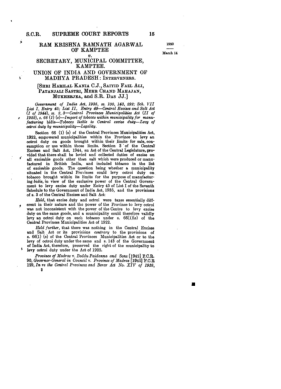

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Get the pixmap from your generator
img = next(doc)

# Convert pixmap samples to a NumPy array
img_array = np.frombuffer(img.samples, dtype=np.uint8).reshape(img.h, img.w, img.n)

# Display with matplotlib
plt.imshow(img_array)
plt.axis("off")  # Optional: hides axis ticks
plt.show()


In [ ]:
system_prompt = """You are a strict OCR character-transcription engine. 
                    Transcribe all visible text from the image accurately. 
                    return output in given formate with sectional hierarchy.
                    """
# system_prompt = """
#                     You are a strict OCR character-transcription engine. 
#                     Transcribe all visible text from the image accurately. 
#                     Preserve line breaks and paragraph spacing as they visually appear, but 
#                     output only raw unformatted text characters.
#                 """
                    
image_bytes = img.tobytes("png")

   
model_input = [
        {
            "prompt": system_prompt,
            "images": [image_bytes]  # Pass raw bytes directly inside the user's message
        }
    ]

In [ ]:
llm = LLM(
    model="deepseek-ai/DeepSeek-OCR",
    enable_prefix_caching=False,
    mm_processor_cache_gb=0,
    logits_processors=[NGramPerReqLogitsProcessor],
    gpu_memory_utilization=0.90,
    cpu_offload_gb=3,
    attention_config=AttentionConfig(backend=AttentionBackendEnum.FLASH_ATTN),

)

INFO 10-03 23:03:04 [api_utils.py:286] non-default args: {'enable_prefix_caching': False, 'cpu_offload_gb': 3, 'gpu_memory_utilization': 0.9, 'disable_log_stats': True, 'mm_processor_cache_gb': 0, 'attention_config': AttentionConfig(backend=<AttentionBackendEnum.FLASH_ATTN: 'vllm.v1.attention.backends.flash_attn.FlashAttentionBackend'>, minimax_m3_msa_decode_backend='triton', backend_per_kind={}, flash_attn_version=None, flash_attn_max_num_splits_for_cuda_graph=32, tq_max_kv_splits_for_cuda_graph=32, use_trtllm_attention=None, disable_flashinfer_q_quantization=False, mla_prefill_backend=None, use_prefill_query_quantization=False, use_fp4_indexer_cache=None, indexer_kv_dtype='auto', use_non_causal=False, sparse_mla_force_mqa=False, flex_attn_block_m=None, flex_attn_block_n=None, flex_attn_q_block_size=None, flex_attn_kv_block_size=None), 'logits_processors': [<class 'vllm.model_executor.models.deepseek_ocr.NGramPerReqLogitsProcessor'>], 'model': 'deepseek-ai/DeepSeek-OCR'}
INFO 10-03 23

Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:21<00:00, 21.72s/it]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:21<00:00, 21.74s/it]
(EngineCore pid=229896) 


(EngineCore pid=229896) INFO 10-03 23:03:48 [default_loader.py:430] Loading weights took 21.78 seconds
(EngineCore pid=229896) INFO 10-03 23:03:48 [unquantized.py:399] Using MoEPrepareAndFinalizeNoDPEPModular
(EngineCore pid=229896) INFO 10-03 23:03:48 [unquantized.py:400] Using TritonExperts MoE backend
(EngineCore pid=229896) INFO 10-03 23:03:50 [gpu_model_runner.py:5471] Model loading took 3.21 GiB memory and 29.611977 seconds
(EngineCore pid=229896) INFO 10-03 23:03:50 [utils.py:306] Using LBNHC KV cache layout.
(EngineCore pid=229896) INFO 10-03 23:03:50 [gpu_model_runner.py:6546] Encoder cache will be initialized with a budget of 8192 tokens, and profiled with 11 image items of the maximum feature size.
(EngineCore pid=229896) INFO 10-03 23:04:33 [caching.py:343] reconstructed serializable fn from standalone compile artifacts. num_artifacts=4 num_submods=13
(EngineCore pid=229896) INFO 10-03 23:04:33 [decorators.py:313] Directly load AOT compilation from path /home/vignesh/.cache

JIT kernel warmup (1 compile keys): 100%|██████████| 1/1 [00:00<00:00, 291.92kernel/s, ComputeSlotMappingKernel (1 keys)]


(EngineCore pid=229896) INFO 10-03 23:04:43 [kernel_warmup.py:134] JIT kernel warmup finished in 0.01s.
(EngineCore pid=229896) INFO 10-03 23:04:44 [kernel_warmup.py:92] Warming up ll_bf16 router GEMM kernels for shapes: ((1280, 64),).
(EngineCore pid=229896) INFO 10-03 23:04:49 [gpu_model_runner.py:6955] Rank 0: Torch profiler disabled for CUDA graph capture


Capturing CUDA graphs (mixed prefill-decode, PIECEWISE): 100%|██████████| 51/51 [00:12<00:00,  3.92it/s]
Capturing CUDA graphs (decode, FULL): 100%|██████████| 35/35 [00:06<00:00,  5.50it/s]


(EngineCore pid=229896) INFO 10-03 23:05:09 [gpu_model_runner.py:7001] Graph capturing finished in 20 secs, took 0.25 GiB
(EngineCore pid=229896) INFO 10-03 23:05:09 [gpu_worker.py:797] CUDA graph pool memory: 0.25 GiB (actual), 0.15 GiB (estimated), difference: 0.1 GiB (39.1%).
(EngineCore pid=229896) INFO 10-03 23:05:09 [gpu_worker.py:860] Free memory on device (7.44/7.53 GiB) on startup. Desired GPU memory utilization is (0.9, 6.77 GiB). Actual usage is 3.7 GiB for consumed memory (weights + non-torch), 0.79 GiB for peak activation, and 0.25 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=2027698996` (1.89 GiB) to fit into requested memory, or `--kv-cache-memory=2738128896` (2.55 GiB) to fully utilize gpu memory. Current kv cache memory in use is 2.28 GiB.
(EngineCore pid=229896) INFO 10-03 23:05:10 [jit_monitor.py:85] Kernel JIT monitor activated; monitored JIT compilations during inference will use mode=warn.
(EngineCore pid=229896) INFO 10-

(EngineCore pid=229896) WARNING 10-03 23:08:17 [jit_monitor.py:141] Triton kernel JIT compilation during inference: apply_token_bitmask_inplace_kernel. This causes a latency spike; consider extending warmup to cover this shape/config.
(EngineCore pid=229896) INFO 10-03 23:12:40 [core.py:1350] [shutdown] EngineCore: trigger received signal=SIGINT
(EngineCore pid=229896) INFO 10-03 23:12:40 [core.py:1501] [shutdown] EngineCore: start mode=abort timeout=0s
(EngineCore pid=229896) INFO 10-03 23:12:40 [core.py:1510] [shutdown] EngineCore: aborting in-flight requests count=1
(EngineCore pid=229896) INFO 10-03 23:12:40 [core.py:1532] [shutdown] EngineCore: request processing complete; starting resource teardown
(EngineCore pid=229896) INFO 10-03 23:12:40 [core.py:1363] [shutdown] EngineCore: exiting busy loop


In [ ]:
image_path_1 = 'inputs/images/sample_image.jpg'
image_path_2 = 'inputs/images/first_30_pages-01.jpg'
image_1 = Image.open(image_path_1)
image_2 = Image.open(image_path_2)
# image_1.show()

# prompt = "<image>\nFree OCR."
# model_input = [
#     {
#         "prompt": prompt,
#         "multi_modal_data": {"image": image_1}
#     },
#     {
#         "prompt": prompt,
#         "multi_modal_data": {"image": image_2}
#     }
# ]



In [ ]:
schema = ResponseFormate.model_json_schema()

In [ ]:
from vllm.sampling_params import StructuredOutputsParams
sampling_param = SamplingParams(
            temperature=0.0,
            max_tokens=8192,
            # ngram logit processor args
            extra_args=dict(
                ngram_size=30,
                window_size=90,
                whitelist_token_ids={128821, 128822},  # whitelist: <td>, </td>
            ),
            skip_special_tokens=False,
            structured_outputs=StructuredOutputsParams(
                                    json=schema
                                )


        )


In [ ]:
outputs = llm.generate(model_input, sampling_param)

Rendering prompts:   0%|          | 0/1 [07:11<?, ?it/s]


KeyboardInterrupt: 

In [ ]:
print(outputs)

In [ ]:
stop_vllm_server()